# ยุคสุดท้ายของแหล่งซากดึกดำบรรพ์: รวมผล notebook 03 และ 04

| ที่มา | วิธี | notebook |
|---|---|---|
| `03 PBDB taxon` | ชื่อสกุลในคำบรรยายแหล่ง → ช่วงอายุของสกุลในไทยตาม PBDB | 03 |
| `03 PBDB nearby` | collection ของ PBDB ที่ใกล้ที่สุด (≤ 10 กม.) | 03 |
| `04 taxon hybrid` | ชนิดตรงตัว → ชนิด fuzzy → สกุล เทียบกับแหล่ง ทธ. ที่รู้ยุคและ PBDB | 04 |

**หลักการรวม**: ไม่ได้ให้วิธีใดมาก่อนเสมอ แต่ใช้**ความแม่นที่วัดได้จริง**ของแต่ละวิธีในแต่ละระดับความเชื่อมั่น
(วัดบนแหล่งที่มี `PERIODFROM` อยู่แล้ว) มาตัดสิน
1. มี `PERIODFROM` เดิม → ใช้ค่าเดิม
2. มีคำทายวิธีเดียว → ใช้วิธีนั้น
3. มีหลายวิธีและ**ตรงกัน** (ช่วงยุคซ้อนทับ) → ใช้ส่วนที่ซ้อนทับกัน (แคบที่สุดที่ทุกวิธียอมรับ)
4. มีหลายวิธีแต่**ขัดกัน** → ใช้วิธีที่แม่นกว่า ติดธง `conflict` เก็บคำทายอีกค่าไว้ใน `alternative`
   และให้ความเชื่อมั่นตามความแม่นที่วัดได้ของ**กรณีขัดกัน** (ไม่ใช่ของวิธีที่ชนะ)

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

DATA = Path("../data")
OUT = DATA / "processed"

_installed = {f.name for f in font_manager.fontManager.ttflist}
THAI_FONT = next((f for f in ["Tahoma", "Thonburi", "Noto Sans Thai", "Leelawadee UI", "Loma", "Garuda"] if f in _installed), None)
plt.rcParams.update({
    "font.family": [THAI_FONT, "DejaVu Sans"] if THAI_FONT else ["DejaVu Sans"], "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
pd.set_option("display.max_columns", 40, "display.max_colwidth", 60, "display.width", 160)
INK, MUTED = "#52514e", "#8a8984"

ORDER = ["Precambrian", "Cambrian", "Ordovician", "Silurian", "Devonian", "Carboniferous", "Permian",
         "Triassic", "Jurassic", "Cretaceous", "Tertiary", "Quaternary"]
RANK = {p: i for i, p in enumerate(ORDER)}
TH_NAME = {"Precambrian": "พรีแคมเบรียน", "Cambrian": "แคมเบรียน", "Ordovician": "ออร์โดวิเชียน", "Silurian": "ไซลูเรียน",
           "Devonian": "ดีโวเนียน", "Carboniferous": "คาร์บอนิเฟอรัส", "Permian": "เพอร์เมียน", "Triassic": "ไทรแอสซิก",
           "Jurassic": "จูแรสซิก", "Cretaceous": "ครีเทเชียส", "Tertiary": "เทอร์เชียรี", "Quaternary": "ควอเทอร์นารี"}


def is_p(x):
    return isinstance(x, str) and x in RANK


def overlaps(a, b):
    # a, b = (old, young)
    return RANK[a[0]] <= RANK[b[1]] and RANK[b[0]] <= RANK[a[1]]


def contains(rng, truth):
    # ช่วงที่ทาย ซ้อนทับช่วงจริงไหม (เกณฑ์เดียวกับ notebook 03/04)
    return overlaps(rng, truth)


def th_label(old, young):
    if not is_p(old):
        return None
    return TH_NAME[old] if old == young else f"{TH_NAME[old]}ถึง{TH_NAME[young]}"

## 1. โหลดผลของ 03 และ 04

ต้องรัน notebook 02 → 03 → 04 ก่อน
- `sites_period_filled.csv` (03): มีคำทายของ `taxon` และ `nearby` สำหรับ**ทุกแหล่ง** รวมแหล่งที่มี `PERIODFROM` แล้ว
- `sites_period_filled_taxon.csv` (04): คำทายของ Hybrid สำหรับแหล่งที่ว่าง
- `eval_taxon_hybrid_loo.csv` (04): คำทายของ Hybrid แบบ leave-one-out บนแหล่งที่รู้ยุค

In [2]:
s03 = pd.read_csv(OUT / "sites_period_filled.csv", dtype={"SITE_CODE": str}, encoding="utf-8-sig")
s04 = pd.read_csv(OUT / "sites_period_filled_taxon.csv", dtype={"SITE_CODE": str}, encoding="utf-8-sig")
loo04 = pd.read_csv(OUT / "eval_taxon_hybrid_loo.csv", encoding="utf-8-sig")
sites = gpd.read_file(OUT / "sites_period_filled.geojson")[["OBJECTID", "geometry"]]

base = s03[["OBJECTID", "SITE_CODE", "NAME_TH", "PROVINCE", "PERIODFROM", "longitude", "latitude",
            "taxon_old", "taxon_young", "nearby_old", "nearby_young", "nearby_confidence", "dist_km", "collection_no"]].copy()
rec = s03.set_index("OBJECTID")
base["rec_old"] = np.where(s03.period_source.eq("DMR record"), s03.period_old, None)
base["rec_young"] = np.where(s03.period_source.eq("DMR record"), s03.period_young, None)

# คำทายของ 04: แหล่งที่ว่างใช้ผลจริง, แหล่งที่รู้ยุคใช้ผล leave-one-out (ไม่ได้เห็นยุคของตัวเอง)
h_missing = s04[["OBJECTID", "pred_H", "period_confidence", "hybrid_level", "vote_share", "evidence"]].dropna(subset=["pred_H"])
h_labeled = loo04.rename(columns={"pred": "pred_H", "level": "hybrid_level", "share": "vote_share"})[
    ["OBJECTID", "pred_H", "period_confidence", "hybrid_level", "vote_share"]].dropna(subset=["pred_H"])
h = pd.concat([h_missing, h_labeled], ignore_index=True).drop_duplicates("OBJECTID")
base = base.merge(h.rename(columns={"period_confidence": "hybrid_confidence"}), on="OBJECTID", how="left")

labeled = base.rec_old.map(is_p)
print(f"แหล่ง {len(base)} | มี PERIODFROM {labeled.sum()} | ว่าง {(~labeled).sum()}")
print("คำทายที่มี (ทุกแหล่ง):", {k: int(base[c].map(is_p).sum()) for k, c in
                               [("03 PBDB taxon", "taxon_old"), ("03 PBDB nearby", "nearby_old"), ("04 taxon hybrid", "pred_H")]})

แหล่ง 518 | มี PERIODFROM 166 | ว่าง 352
คำทายที่มี (ทุกแหล่ง): {'03 PBDB taxon': 43, '03 PBDB nearby': 270, '04 taxon hybrid': 161}


## 2. ตารางคำทาย (candidate) ต่อแหล่ง

แต่ละแหล่งมีคำทายได้สูงสุด 3 ค่า แต่ละค่ามี `(old, young)` และระดับความเชื่อมั่นตามที่ notebook ต้นทางกำหนด

In [3]:
cands = []
for r in base.itertuples():
    if is_p(r.taxon_old):
        cands.append((r.OBJECTID, "03 PBDB taxon", "high", r.taxon_old, r.taxon_young))
    if is_p(r.nearby_old):
        cands.append((r.OBJECTID, "03 PBDB nearby", r.nearby_confidence, r.nearby_old, r.nearby_young))
    if is_p(r.pred_H):
        cands.append((r.OBJECTID, "04 taxon hybrid", r.hybrid_confidence, r.pred_H, r.pred_H))
C = pd.DataFrame(cands, columns=["OBJECTID", "method", "tier", "old", "young"])
C = C.merge(base[["OBJECTID", "rec_old", "rec_young"]], on="OBJECTID")
C["labeled"] = C.rec_old.map(is_p)
C["correct"] = [contains((o, y), (ro, ry)) if lab else np.nan for o, y, ro, ry, lab in zip(C.old, C.young, C.rec_old, C.rec_young, C.labeled)]
pd.crosstab([C.method, C.tier], C.labeled.map({True: "แหล่งที่รู้ยุค", False: "แหล่งที่ว่าง"}))

labeled                 แหล่งที่รู้ยุค  แหล่งที่ว่าง
method          tier                                
03 PBDB nearby  high                35            63
                low                 25            58
                medium              23            66
03 PBDB taxon   high                11            32
04 taxon hybrid high                20            48
                low                  2            10
                medium              22            59

### 2b. ตรวจความเป็นไปได้กับซากในแหล่ง

ซากบางกลุ่มบอกช่วงอายุได้ชัด คำทายที่อยู่นอกช่วงของซากที่พบในแหล่ง**เป็นไปไม่ได้** (เช่น รอยตีนไดโนเสาร์ = เพอร์เมียน)
→ ตัดคำทายนั้นทิ้งก่อนรวม: ถ้ามีวิธีอื่นที่สอดคล้องจะใช้แทน ไม่งั้นเว้นว่าง (ตามที่ EDA ใน notebook 06 แนะนำ; ไม่แก้ `PERIODFROM` ที่ ทธ. บันทึก)

| ซาก | ช่วงที่เป็นไปได้ |
|---|---|
| ไดโนเสาร์ | ไทรแอสซิก–ครีเทเชียส |
| สัตว์เลี้ยงลูกด้วยนม | ไทรแอสซิก–ควอเทอร์นารี |
| ไทรโลไบต์ | แคมเบรียน–เพอร์เมียน |
| แกรปโตไลต์ | แคมเบรียน–คาร์บอนิเฟอรัส |

หลักฐานซาก = คำในชื่อ/คำบรรยายแหล่ง หรือตัวอย่างในทะเบียนที่เชื่อมแหล่งระดับ**ตำแหน่ง** (`locality`) ด้วยความเชื่อมั่น `high`
— ตัวอย่างที่เชื่อมระดับตำบลลงไปอาจอยู่ผิดแหล่งแม้ได้ `high` (ตอนลองใช้ระดับตำบลด้วย พบไทรโลไบต์ที่เชื่อมผิดเข้าถ้ำแพนด้า
และแกรปโตไลต์เข้าแหล่งหอยนางรมจูแรสซิก ทำให้ตัดคำทายที่ถูกทิ้ง) จึงไม่ใช้ตัดสิน; ชื่อกลุ่มซากใช้กฎเดียวกับงาน 2 (`feature_lib.classes_of`)

In [4]:
import feature_lib as fl

AGE_RANGE = {"ไดโนเสาร์": ("Triassic", "Cretaceous"), "สัตว์เลี้ยงลูกด้วยนม": ("Triassic", "Quaternary"),
             "ไทรโลไบต์": ("Cambrian", "Permian"), "แกรปโตไลต์": ("Cambrian", "Carboniferous")}
raw = gpd.read_file(DATA / "dmr_fossil_sites" / "fossil_sites.geojson")[["OBJECTID", "NAME_TH", "FOS_DES_TH"]]
evid = {int(o): fl.classes_of(f"{n or ''} {d or ''}") & set(AGE_RANGE) for o, n, d in zip(raw.OBJECTID, raw.NAME_TH, raw.FOS_DES_TH)}
mrg = pd.read_csv(OUT / "fossil_list_merged.csv", dtype={"fossil_id": str, "tied_site_ids": str}, encoding="utf-8-sig", low_memory=False)
strong = mrg[mrg.confidence.eq("high") & mrg.match_level.eq("locality") & mrg.tied_site_ids.notna()]
for ids, t, c in zip(strong.tied_site_ids, strong.f_type, strong.com_name):
    for sid in str(ids).split(";"):
        evid.setdefault(int(float(sid)), set()).update(fl.specimen_classes(t, c) & set(AGE_RANGE))


def implausible(oid, old, young):
    # ซากที่ช่วง (old, young) ของคำทายไม่ทับกับช่วงอายุที่เป็นไปได้
    bad = [c for c in evid.get(oid, ()) if RANK[young] < RANK[AGE_RANGE[c][0]] or RANK[old] > RANK[AGE_RANGE[c][1]]]
    return ", ".join(sorted(bad)) or None


C["implausible"] = [implausible(o, a, b) for o, a, b in zip(C.OBJECTID, C.old, C.young)]
REJECTED = C[C.implausible.notna()].merge(base[["OBJECTID", "NAME_TH"]], on="OBJECTID")
print(f"แหล่งที่มีหลักฐานซากบอกอายุ {sum(bool(v) for v in evid.values())} | คำทายที่ขัดกับซาก {len(REJECTED)} "
      f"(แหล่งที่รู้ยุค {int(REJECTED.labeled.sum())}, แหล่งที่ว่าง {int((~REJECTED.labeled).sum())}) -> ตัดทิ้ง")
display(REJECTED[["OBJECTID", "NAME_TH", "method", "tier", "old", "young", "implausible", "labeled", "correct"]])
REJECTED_TXT = REJECTED.groupby("OBJECTID").apply(
    lambda g: "; ".join(f"{m}: {th_label(o, y)} (ขัดกับ{c})" for m, o, y, c in zip(g.method, g.old, g.young, g.implausible)), include_groups=False)
C = C[C.implausible.isna()].drop(columns="implausible").reset_index(drop=True)

แหล่งที่มีหลักฐานซากบอกอายุ 127 | คำทายที่ขัดกับซาก 5 (แหล่งที่รู้ยุค 1, แหล่งที่ว่าง 4) -> ตัดทิ้ง


,OBJECTID,NAME_TH,method,tier,old,young,implausible,labeled,correct
0,11198,สัตว์ไม่มีกระดูกสันหลังอ่าวสน,03 PBDB nearby,high,Quaternary,Quaternary,ไทรโลไบต์,False,NaN
1,11251,สัตว์ไม่มีกระดูกสันหลังเขาศรีอินทร์,03 PBDB nearby,medium,Jurassic,Jurassic,ไทรโลไบต์,False,NaN
2,11276,แบรคิโอพอดบ้านควนดินสอ,03 PBDB nearby,low,Triassic,Triassic,ไทรโลไบต์,True,False
3,11283,ไดโนเสาร์แก่งหลวง,03 PBDB nearby,low,Tertiary,Tertiary,ไดโนเสาร์,False,NaN
4,11436,รอยตีนไดโนเสาร์ลำน้ำหมันแดง,04 taxon hybrid,medium,Permian,Permian,ไดโนเสาร์,False,NaN


## 3. วัดความแม่นของแต่ละวิธี × ระดับ

ใช้แหล่งที่รู้ยุค ตัวอย่างบางกลุ่มมีน้อย จึงใช้ **ความแม่นแบบปรับเรียบ** `(ถูก + 1) / (n + 2)` ในการจัดอันดับ
(กลุ่มที่มีตัวอย่างน้อยจะถูกดึงเข้าหา 50% ไม่ได้คะแนนสูงเพราะบังเอิญ) และแสดงช่วงความเชื่อมั่น 95% (Wilson) ไว้ประกอบ

,method,tier,n,k,accuracy,smoothed,ci_low,ci_high
0,03 PBDB nearby,high,35,31,89%,86%,74%,95%
1,03 PBDB nearby,medium,23,19,83%,80%,63%,93%
2,03 PBDB nearby,low,24,17,71%,69%,51%,85%
3,03 PBDB taxon,high,11,8,73%,69%,43%,90%
4,04 taxon hybrid,high,20,16,80%,77%,58%,92%
5,04 taxon hybrid,medium,22,19,86%,83%,67%,95%
6,04 taxon hybrid,low,2,1,50%,50%,9%,91%


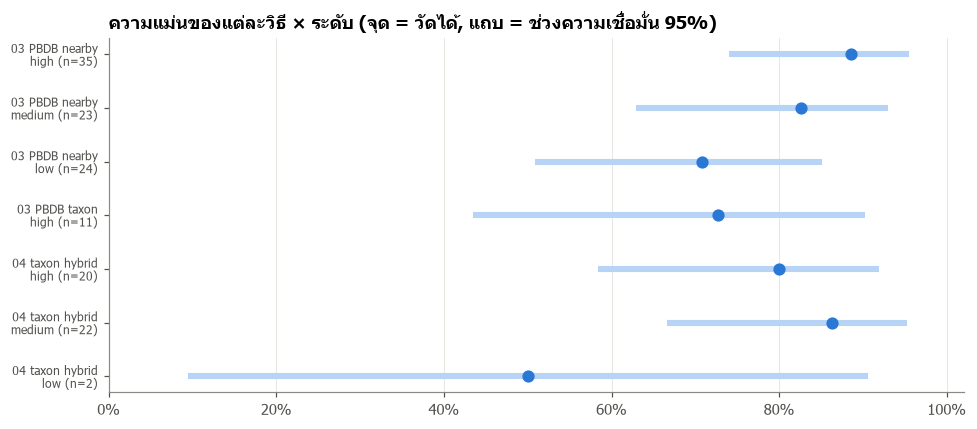

In [5]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    m = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - m, c + m)


cal = C[C.labeled].groupby(["method", "tier"]).correct.agg(n="size", k="sum").reset_index()
cal["accuracy"] = cal.k / cal.n
cal["smoothed"] = (cal.k + 1) / (cal.n + 2)
cal[["ci_low", "ci_high"]] = [wilson(k, n) for k, n in zip(cal.k, cal.n)]
TIER_ORDER = {"high": 0, "medium": 1, "low": 2}
cal = cal.sort_values(["method", "tier"], key=lambda s: s.map(TIER_ORDER) if s.name == "tier" else s).reset_index(drop=True)
ACC = {(m, t): a for m, t, a in zip(cal.method, cal.tier, cal.smoothed)}
display(cal.style.format({"accuracy": "{:.0%}", "smoothed": "{:.0%}", "ci_low": "{:.0%}", "ci_high": "{:.0%}", "k": "{:.0f}"}))

fig, ax = plt.subplots(figsize=(9, 4))
labels = [f"{m}\n{t} (n={n})" for m, t, n in zip(cal.method, cal.tier, cal.n)]
y = np.arange(len(cal))[::-1]
ax.errorbar(cal.accuracy, y, xerr=[cal.accuracy - cal.ci_low, cal.ci_high - cal.accuracy], fmt="o", color="#2a78d6",
            ecolor="#b7d3f6", elinewidth=4, capsize=0, ms=7)
ax.set_yticks(y, labels, fontsize=8)
ax.set_xlim(0, 1.02)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title("ความแม่นของแต่ละวิธี × ระดับ (จุด = วัดได้, แถบ = ช่วงความเชื่อมั่น 95%)")
ax.grid(axis="y", visible=False)
plt.tight_layout()

ช่วงความเชื่อมั่นกว้าง เพราะแต่ละกลุ่มมีแหล่งที่ตรวจได้แค่หลักสิบ ลำดับความแม่นจึงเป็นแนวโน้ม ไม่ใช่ความต่างที่ชัดเจนทางสถิติ

## 4. กฎการรวม และทดสอบบนแหล่งที่รู้ยุค

In [6]:
def combine(group):
    # group: คำทายทั้งหมดของ 1 แหล่ง -> dict ผลรวม
    g = group.assign(acc=[ACC.get((m, t), 0.5) for m, t in zip(group.method, group.tier)]).sort_values("acc", ascending=False)
    best = g.iloc[0]
    rngs = list(zip(g.old, g.young))
    if len(g) == 1:
        return dict(final_old=best.old, final_young=best.young, final_source=best.method, agreement="single",
                    est_accuracy=best.acc, alternative=None)
    if all(overlaps(rngs[0], r) for r in rngs[1:]):
        lo = max((RANK[o] for o, _ in rngs))
        hi = min((RANK[y] for _, y in rngs))
        old, young = (ORDER[lo], ORDER[hi]) if lo <= hi else (best.old, best.young)
        return dict(final_old=old, final_young=young, final_source=" + ".join(sorted(g.method)), agreement="agree",
                    est_accuracy=None, alternative=None)
    others = g.iloc[1:]
    alt = "; ".join(f"{m}: {th_label(o, y)}" for m, o, y in zip(others.method, others.old, others.young) if not overlaps(rngs[0], (o, y)))
    return dict(final_old=best.old, final_young=best.young, final_source=best.method, agreement="conflict",
                est_accuracy=best.acc, alternative=alt)


combined = pd.DataFrame([{"OBJECTID": oid, **combine(g)} for oid, g in C.groupby("OBJECTID")])
combined = combined.merge(base[["OBJECTID", "rec_old", "rec_young"]], on="OBJECTID")
combined["labeled"] = combined.rec_old.map(is_p)
combined["correct"] = [contains((o, y), (ro, ry)) if lab else np.nan
                       for o, y, ro, ry, lab in zip(combined.final_old, combined.final_young, combined.rec_old, combined.rec_young, combined.labeled)]

# ความแม่นของกรณี "ตรงกัน" และ "ขัดกัน" วัดจากแหล่งที่รู้ยุค (ปรับเรียบ) แล้วใช้เป็น est_accuracy ของกรณีนั้น
# กรณีขัดกันใช้ค่าของตัวเอง เพราะความแม่นของวิธีที่ชนะไม่ได้สะท้อนว่าอีกวิธีบอกคนละยุค
def smoothed_acc(df):
    return (df.correct.sum() + 1) / (len(df) + 2)


AGREE_ACC = smoothed_acc(combined[combined.labeled & combined.agreement.eq("agree")])
CONFLICT_ACC = smoothed_acc(combined[combined.labeled & combined.agreement.eq("conflict")])
combined.loc[combined.agreement.eq("agree"), "est_accuracy"] = AGREE_ACC
combined.loc[combined.agreement.eq("conflict"), "est_accuracy"] = CONFLICT_ACC

lab = combined[combined.labeled]
display(lab.groupby("agreement").correct.agg(n="size", accuracy="mean").reindex(["agree", "single", "conflict"]).style.format({"accuracy": "{:.0%}"}))

# เทียบกับใช้วิธีเดียว บนแหล่งที่รู้ยุคชุดเดียวกัน (แหล่งที่มีคำทายอย่างน้อย 1 วิธี)
units = set(lab.OBJECTID)
rows = [{"วิธี": "รวม (กฎข้างบน)", "ทายได้": len(lab), "ถูก": lab.correct.mean()}]
for m in ["03 PBDB taxon", "03 PBDB nearby", "04 taxon hybrid"]:
    sub = C[C.labeled & C.method.eq(m)]
    rows.append({"วิธี": m, "ทายได้": len(sub), "ถูก": sub.correct.mean()})
cmp_tbl = pd.DataFrame(rows)
cmp_tbl["ถูกจากทั้งหมด"] = cmp_tbl["ทายได้"] * cmp_tbl["ถูก"] / len(units)
print(f"แหล่งที่รู้ยุคและมีคำทายอย่างน้อย 1 วิธี: {len(units)} | est. accuracy: ตรงกัน {AGREE_ACC:.0%}, ขัดกัน {CONFLICT_ACC:.0%}")
cmp_tbl.style.format({"ถูก": "{:.0%}", "ถูกจากทั้งหมด": "{:.0%}"})

,n,accuracy
agreement,,
agree,30,87%
single,63,83%
conflict,4,25%


แหล่งที่รู้ยุคและมีคำทายอย่างน้อย 1 วิธี: 97 | est. accuracy: ตรงกัน 84%, ขัดกัน 33%


,วิธี,ทายได้,ถูก,ถูกจากทั้งหมด
0,รวม (กฎข้างบน),97,81%,81%
1,03 PBDB taxon,11,73%,8%
2,03 PBDB nearby,82,82%,69%
3,04 taxon hybrid,44,82%,37%


**ข้อควรระวัง**: ความแม่นในส่วนนี้วัดบนข้อมูลชุดเดียวกับที่ใช้ปรับเทียบ (`ACC`) จึงอาจสูงกว่าความจริงเล็กน้อย
แต่กฎการรวมใช้ `ACC` แค่ตัดสินว่าใครชนะเมื่อขัดกัน ซึ่งเกิดไม่บ่อย จึงได้รับผลน้อย

## 5. ยุคสุดท้าย

กรณีขัดกันมีความแม่นต่ำมาก จึงได้ความเชื่อมั่น `low` เสมอ ตรวจดูรายการด้านล่างก่อนนำไปใช้
หลายรายการน่าจะมาจากตัวอย่างที่ถูกเชื่อมผิดแหล่งใน notebook 02 — คำทายที่เป็นไปไม่ได้ตามซากในแหล่ง (เช่น รอยตีนไดโนเสาร์ = เพอร์เมียน)
ถูกตัดไปแล้วในส่วน 2b (ดูคอลัมน์ `rejected_by_fossils`)

In [7]:
def final_conf(acc):
    if pd.isna(acc):
        return None
    return "high" if acc >= 0.85 else "medium" if acc >= 0.75 else "low"


final = base[["OBJECTID", "SITE_CODE", "NAME_TH", "PROVINCE", "PERIODFROM", "rec_old", "rec_young"]].merge(
    combined.drop(columns=["rec_old", "rec_young", "labeled", "correct"]), on="OBJECTID", how="left")
is_rec = final.rec_old.map(is_p)
final.loc[is_rec, ["final_old", "final_young"]] = final.loc[is_rec, ["rec_old", "rec_young"]].values
final.loc[is_rec, ["final_source", "agreement", "est_accuracy", "alternative"]] = ["DMR record", "recorded", np.nan, None]
final["PERIOD_FINAL"] = np.where(is_rec, final.PERIODFROM, [th_label(o, y) for o, y in zip(final.final_old, final.final_young)])
final["final_confidence"] = np.where(is_rec, "recorded", final.est_accuracy.map(final_conf))
final.loc[final.PERIOD_FINAL.isna(), ["final_source", "final_confidence"]] = ["missing", None]
# คำทายที่ขัดกันกับ PERIODFROM เดิม (เช่น ถ้ำ: บันทึกอายุหิน แต่ซากเป็นยุคควอเทอร์นารี) เก็บไว้ดูได้
rec_conf = C[C.labeled & C.correct.eq(False)].groupby("OBJECTID").apply(
    lambda g: "; ".join(f"{m}: {th_label(o, y)}" for m, o, y in zip(g.method, g.old, g.young)), include_groups=False)
final["disagrees_with_record"] = final.OBJECTID.map(rec_conf)
final["rejected_by_fossils"] = final.OBJECTID.map(REJECTED_TXT)               # คำทายที่ตัดทิ้งในส่วน 2b

missing_before = (~is_rec).sum()
missing_after = final.PERIOD_FINAL.isna().sum()
print(f"PERIODFROM ว่าง: {missing_before} ({missing_before / len(final):.0%}) → {missing_after} ({missing_after / len(final):.0%}) แหล่ง")
display(pd.crosstab(final.final_source, final.final_confidence.fillna("-")).reindex(
    columns=[c for c in ["recorded", "high", "medium", "low", "-"] if c in set(final.final_confidence.fillna("-"))]))
print("แหล่งที่เติมแล้วแต่คำทายขัดกัน:", int(final.agreement.eq("conflict").sum()))
print("แหล่งที่ตัดคำทายที่ขัดกับซาก (ส่วน 2b):")
display(final[final.rejected_by_fossils.notna()][["NAME_TH", "PROVINCE", "PERIOD_FINAL", "final_source", "final_confidence", "rejected_by_fossils"]])
final[final.agreement.eq("conflict")][["NAME_TH", "PROVINCE", "PERIOD_FINAL", "final_source", "alternative"]]

PERIODFROM ว่าง: 352 (68%) → 129 (25%) แหล่ง


final_confidence,recorded,high,medium,low,-
final_source,,,,,
03 PBDB nearby,0,20,40,54,0
03 PBDB nearby + 03 PBDB taxon + 04 taxon hybrid,0,0,24,0,0
03 PBDB nearby + 04 taxon hybrid,0,0,39,0,0
03 PBDB taxon + 04 taxon hybrid,0,0,6,0,0
04 taxon hybrid,0,0,28,12,0
DMR record,166,0,0,0,0
missing,0,0,0,0,129


แหล่งที่เติมแล้วแต่คำทายขัดกัน: 14
แหล่งที่ตัดคำทายที่ขัดกับซาก (ส่วน 2b):


,NAME_TH,PROVINCE,PERIOD_FINAL,final_source,final_confidence,rejected_by_fossils
23,สัตว์ไม่มีกระดูกสันหลังอ่าวสน,สตูล,แคมเบรียน,04 taxon hybrid,medium,03 PBDB nearby: ควอเทอร์นารี (ขัดกับไทรโลไบต์)
76,สัตว์ไม่มีกระดูกสันหลังเขาศรีอินทร์,นครศรีธรรมราช,ออร์โดวิเชียน,04 taxon hybrid,low,03 PBDB nearby: จูแรสซิก (ขัดกับไทรโลไบต์)
101,แบรคิโอพอดบ้านควนดินสอ,พัทลุง,คาร์บอนิเฟอรัส,DMR record,recorded,03 PBDB nearby: ไทรแอสซิก (ขัดกับไทรโลไบต์)
108,ไดโนเสาร์แก่งหลวง,พะเยา,NaN,missing,NaN,03 PBDB nearby: เทอร์เชียรี (ขัดกับไดโนเสาร์)
260,รอยตีนไดโนเสาร์ลำน้ำหมันแดง,เลย,ครีเทเชียส,03 PBDB nearby,medium,04 taxon hybrid: เพอร์เมียน (ขัดกับไดโนเสาร์)


,NAME_TH,PROVINCE,PERIOD_FINAL,final_source,alternative
24,แบรคิโอพอดเกาะกลาง,สตูล,ออร์โดวิเชียน,03 PBDB nearby,04 taxon hybrid: เพอร์เมียน
42,แบรคิโอพอดห้วยหลวง,เลย,คาร์บอนิเฟอรัส,03 PBDB nearby,04 taxon hybrid: เพอร์เมียน
94,สัตว์ไม่มีกระดูกสันหลังดอยผาพลึง,ลำปาง,เพอร์เมียน,03 PBDB nearby,04 taxon hybrid: ไทรแอสซิก
109,ไดโนเสาร์ภูนกเขียน,ขอนแก่น,ครีเทเชียส,03 PBDB nearby,03 PBDB taxon: จูแรสซิก
132,สัตว์ไม่มีกระดูกสันหลังเหมืองหินปูนศิลาผาทอง,เลย,เพอร์เมียน,04 taxon hybrid,03 PBDB nearby: ไทรแอสซิก
164,สัตว์ไม่มีกระดูกสันหลังบ้านห้วยตาด,เลย,เพอร์เมียน,04 taxon hybrid,03 PBDB nearby: คาร์บอนิเฟอรัส
188,แอมโมนอยด์บ้านแก่งหลวง,แพร่,ไทรแอสซิก,04 taxon hybrid,03 PBDB nearby: เพอร์เมียน
226,สำนักสงฆ์สีหนาทเดชา,ชัยภูมิ,เพอร์เมียน,04 taxon hybrid,03 PBDB nearby: ไทรแอสซิก
231,แบรคิโอพอดบ้านสูบ,เลย,เพอร์เมียน,04 taxon hybrid,03 PBDB nearby: คาร์บอนิเฟอรัส
232,สัตว์ไม่มีกระดูกสันหลังผาจอมนาง,เลย,ดีโวเนียน,03 PBDB nearby,04 taxon hybrid: เพอร์เมียน


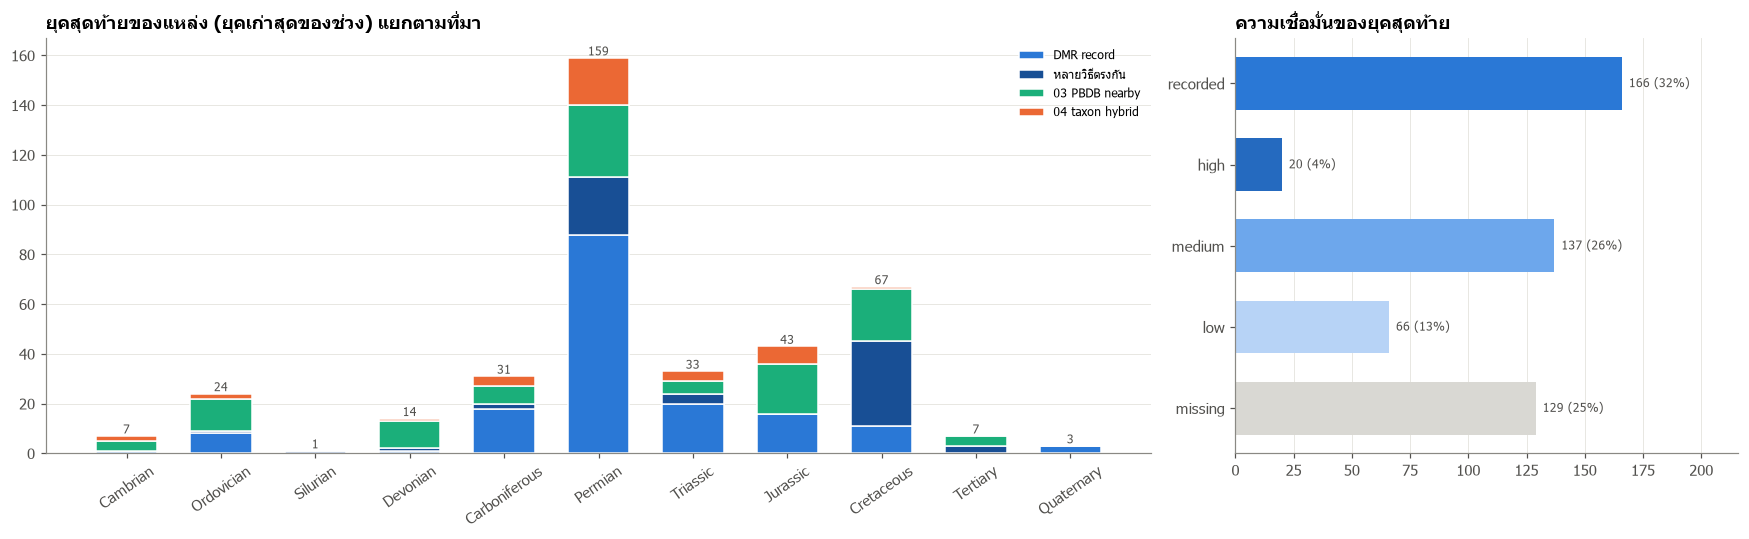

In [8]:
src_simple = final.final_source.where(final.final_source.isin(["DMR record", "missing"]),
                                      np.where(final.agreement.eq("agree"), "หลายวิธีตรงกัน", final.final_source))
counts = pd.crosstab(final.final_old.where(final.PERIOD_FINAL.notna()), src_simple).reindex(
    [p for p in ORDER if p in set(final.final_old.dropna())])
cols = [c for c in ["DMR record", "หลายวิธีตรงกัน", "03 PBDB taxon", "03 PBDB nearby", "04 taxon hybrid"] if c in counts]
colors = {"DMR record": "#2a78d6", "หลายวิธีตรงกัน": "#184f95", "03 PBDB taxon": "#eda100", "03 PBDB nearby": "#1baf7a", "04 taxon hybrid": "#eb6834"}

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2.2, 1]})
bottom = np.zeros(len(counts))
for c in cols:
    axes[0].bar(counts.index, counts[c], bottom=bottom, color=colors[c], label=c, width=0.65, edgecolor="white", linewidth=1)
    bottom += counts[c].values
for x, v in enumerate(bottom):
    axes[0].text(x, v, f"{v:.0f}", ha="center", va="bottom", fontsize=8, color=INK)
axes[0].set_title("ยุคสุดท้ายของแหล่ง (ยุคเก่าสุดของช่วง) แยกตามที่มา")
axes[0].tick_params(axis="x", rotation=35)
axes[0].grid(axis="x", visible=False)
axes[0].legend(frameon=False, fontsize=8)

conf = final.final_confidence.fillna("missing").value_counts().reindex(["recorded", "high", "medium", "low", "missing"]).fillna(0)
cc = {"recorded": "#2a78d6", "high": "#256abf", "medium": "#6da7ec", "low": "#b7d3f6", "missing": "#d9d8d3"}
axes[1].barh(conf.index[::-1], conf.values[::-1], color=[cc[k] for k in conf.index[::-1]], height=0.65)
for yv, v in enumerate(conf.values[::-1]):
    axes[1].text(v + 3, yv, f"{v:.0f} ({v / len(final):.0%})", va="center", fontsize=8, color=INK)
axes[1].set_xlim(0, conf.max() * 1.3)
axes[1].set_title("ความเชื่อมั่นของยุคสุดท้าย")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()

## 6. บันทึกผล

- `data/processed/sites_period_final.csv` / `.geojson`: แหล่งทั้ง 518 แห่ง
  - `PERIODFROM` เดิม (ไม่แก้) | **`PERIOD_FINAL`** (ภาษาไทย) | `final_old` / `final_young` (ชื่อยุคมาตรฐาน)
  - `final_source`: `DMR record`, ชื่อวิธี, หรือหลายวิธีต่อกันด้วย ` + ` เมื่อตรงกัน
  - `agreement` (recorded / single / agree / conflict), `est_accuracy`, `final_confidence`, `alternative`
  - `disagrees_with_record`: แหล่งที่มี `PERIODFROM` แล้วแต่วิธีอื่นทายต่าง (มักเป็นถ้ำ: อายุหิน vs อายุซาก)
  - `rejected_by_fossils`: คำทายที่ตัดทิ้งเพราะขัดกับช่วงอายุของซากในแหล่ง (ส่วน 2b)
- `data/processed/fossil_list_final.csv`: ทะเบียนตัวอย่างที่เชื่อมแหล่งแล้ว (notebook 02) + ยุคสุดท้ายของแหล่ง

`final_confidence` มาจาก `est_accuracy`: high ≥ 85%, medium 75–85%, low < 75%

In [9]:
out_cols = ["OBJECTID", "SITE_CODE", "NAME_TH", "PROVINCE", "PERIODFROM", "PERIOD_FINAL", "final_old", "final_young",
            "final_source", "agreement", "est_accuracy", "final_confidence", "alternative", "disagrees_with_record", "rejected_by_fossils"]
res = sites.merge(final[out_cols], on="OBJECTID")
res = gpd.GeoDataFrame(res, geometry="geometry", crs=4326)
res.to_file(OUT / "sites_period_final.geojson", driver="GeoJSON")
res.drop(columns="geometry").assign(longitude=res.geometry.x, latitude=res.geometry.y).to_csv(
    OUT / "sites_period_final.csv", index=False, encoding="utf-8-sig")

m = pd.read_csv(OUT / "fossil_list_merged.csv", dtype={"fossil_id": str, "SITE_CODE": str, "site_SITE_CODE": str, "site_OBJECTID": "Int64"}, encoding="utf-8-sig", low_memory=False)
add = final[["OBJECTID", "PERIOD_FINAL", "final_old", "final_young", "final_source", "final_confidence"]].rename(columns=lambda c: "site_" + c)
m = m.merge(add, on="site_OBJECTID", how="left")
m.to_csv(OUT / "fossil_list_final.csv", index=False, encoding="utf-8-sig")
has = m.site_OBJECTID.notna()
print(f"บันทึก sites_period_final ({len(res)} แหล่ง) และ fossil_list_final ({len(m):,} ตัวอย่าง)")
print(f"ตัวอย่างที่เชื่อมแหล่งได้ {has.sum():,} ชิ้น | มียุคของแหล่ง: เดิม {m.loc[has, 'site_PERIODFROM'].notna().sum():,} → สุดท้าย {m.loc[has, 'site_PERIOD_FINAL'].notna().sum():,}")

บันทึก sites_period_final (518 แหล่ง) และ fossil_list_final (8,521 ตัวอย่าง)
ตัวอย่างที่เชื่อมแหล่งได้ 7,853 ชิ้น | มียุคของแหล่ง: เดิม 2,283 → สุดท้าย 7,344


## 7. ข้อจำกัด

- **การปรับเทียบใช้ตัวอย่างน้อย** (หลักสิบต่อกลุ่ม) ระดับความเชื่อมั่นจึงเป็นค่าประมาณ ไม่ใช่ความน่าจะเป็นที่แม่นยำ
- **03 PBDB taxon กับ 04 ใช้หลักฐานซ้อนกัน** (ชื่อละตินในคำบรรยายแหล่ง) เมื่อสองวิธีนี้ตรงกันจึงไม่ได้ยืนยันกันอย่างอิสระเต็มที่
- **`PERIOD_FINAL` ยังปนอายุหินกับอายุซาก** ในแหล่งที่ใช้ `PERIODFROM` เดิม ดูคอลัมน์ `disagrees_with_record` เพื่อหาแหล่งแบบถ้ำ
- **แหล่งที่ยังว่าง** ไม่มีทั้งชื่อซากและ PBDB ในรัศมี 10 กม. ถ้าต้องการให้ครบทุกแหล่ง ใช้แผนที่หน่วยหินเติมได้ (notebook 01 ส่วนที่ 5) แต่จะเป็นอายุหิน